# Resultados del experimento final: Conv + BiLSTM conjunta vs BiRNN

Compara los dos modelos del experimento final, entrenados en paralelo con `final_joint_20_epocas.ipynb` y
`final_birnn_dropout_cabeza.ipynb` (rama `feat/birnn-cabeza-no-lineal`). Los dos mantienen la configuración del
candidato final (`class_weight_power = 0.25`, weight decay 0.1 en la BiRNN de puntuación, ~62 mil instancias de
train) y cambian:

- `models/corridas/2026-11-18__04-38-20/`: `joint_conv_bilstm` con **20 épocas** (antes 10).
- `models/corridas/2026-11-18__04-44-00/`: `bidirectional_rnn` con **15 épocas, dropout 0.3 y cabeza no lineal**
  (`Linear 256 → 128 → GELU → Dropout → Linear 128 → clases`; antes 10 épocas, sin dropout y cabeza lineal).

El notebook las junta en `models/final/metrics.json` y guarda cada gráfico en PNG y PDF en
`models/final/poster/`. El candidato final (`models/precandidato_final/`) no se toca.

**Se compara sobre control**: test ya se usó para elegir la época de cada red, así que su F1 es optimista.

In [1]:
import os
from pathlib import Path

# El notebook corre desde notebooks/experiments/: subimos hasta la raíz del repo para importar src
while not Path("pyproject.toml").exists():
    os.chdir("..")

import json

import matplotlib.pyplot as plt
from IPython.display import display

from notebooks.experiments import candidato_final_plots as C
from src.poster import plots as P

%matplotlib inline

/home/sebastian/personal/uba/Aprendizaje-Automatico-UBA/tp/TP2-Aprendizaje-Automatico-UBA/.venv/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Configuración

In [2]:
RUNS = [Path("models/corridas/2026-11-18__04-44-00"), Path("models/corridas/2026-11-18__04-38-20")]
# Se compara contra el candidato final (las dos corridas de 10 épocas ya unidas)
PREVIOUS = [Path("models/precandidato_final")]
SPLIT = "control"  # "control" (recomendado) o "test"

RUN_DIR = Path("models/final")
OUT_DIR = RUN_DIR / "poster"


def show_and_save(fig, name: str, caption: bool = True) -> None:
    """Muestra el gráfico y lo guarda en OUT_DIR como PNG y PDF"""
    if caption:
        P.add_caption(fig, CAPTION)
    P.save_figure(fig, OUT_DIR, name)
    display(fig)
    plt.close(fig)

In [3]:
report = C.merge_runs(RUNS)
# Cada modelo se entrenó con distinta cantidad de épocas: merge_runs se queda con la config de la primera corrida
report["config"]["n_epochs"] = "20 (conjunta) y 15 (BiRNN)"
RUN_DIR.mkdir(parents=True, exist_ok=True)
(RUN_DIR / "metrics.json").write_text(json.dumps(report, ensure_ascii=False, indent=1), encoding="utf-8")

config = report["config"]
print("Corridas:", config["merged_from"])
print("class_weight_power:", config["class_weight_power"], "· weight decay BiRNN:", config["bidirectional_rnn_weight_decay"])
for problem, models in report["problems"].items():
    for model, r in models.items():
        if r:
            print(f"{problem} · {model}: mejor época {r['best_epoch']}/{len(r['history'])}")
CAPTION = P.data_caption(report)
print(CAPTION)
print()
for split in ("control", "test"):
    print(f"F1 macro en {split}")
    print(P.f1_table(report, split))
    print()

Corridas: ['2026-11-18__04-44-00', '2026-11-18__04-38-20']
class_weight_power: 0.25 · weight decay BiRNN: {'CapitalizationProblem': 0.0, 'PunctuationProblem': 0.1}
CapitalizationProblem · bidirectional_rnn: mejor época 15/15
CapitalizationProblem · joint_conv_bilstm: mejor época 18/20
PunctuationProblem · bidirectional_rnn: mejor época 14/15
PunctuationProblem · joint_conv_bilstm: mejor época 18/20
Datos: train 61.912 instancias (2.011.914 palabras), test 15.477, control 19.347 por problema · ventanas de 5–60 palabras · redes: 20 (conjunta) y 15 (BiRNN) épocas

F1 macro en control
modelo                            Capitalización  Puntuación inicial    Puntuación final  promedio
Conv + BiLSTM conjunta                     0.788               0.858               0.716     0.787
BiRNN                                      0.728               0.833               0.657     0.739

F1 macro en test
modelo                            Capitalización  Puntuación inicial    Puntuación final  promedi

## 1. ¿Mejoró respecto del candidato final?

F1 macro de cada tarea contra el candidato final del mismo modelo.

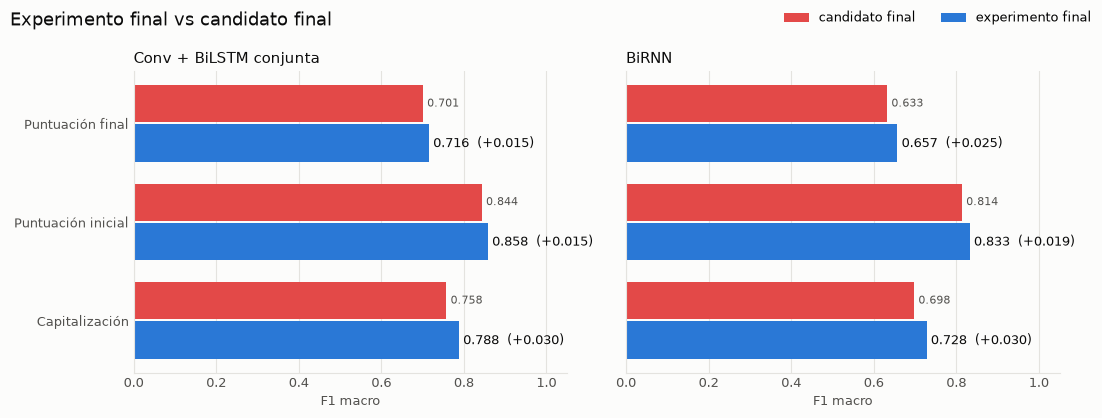

In [4]:
before = C.best_previous(PREVIOUS, SPLIT)
after = C.control_scores(report, SPLIT)
labels = ("candidato final", "experimento final")
fig = C.plot_before_after(before, after, labels, "Experimento final vs candidato final")
show_and_save(fig, "1_antes_vs_despues", caption=False)

## 2. F1 macro por tarea

Es la métrica del enunciado. Los modelos van del mejor (arriba) al peor según el promedio de las 3 tareas.

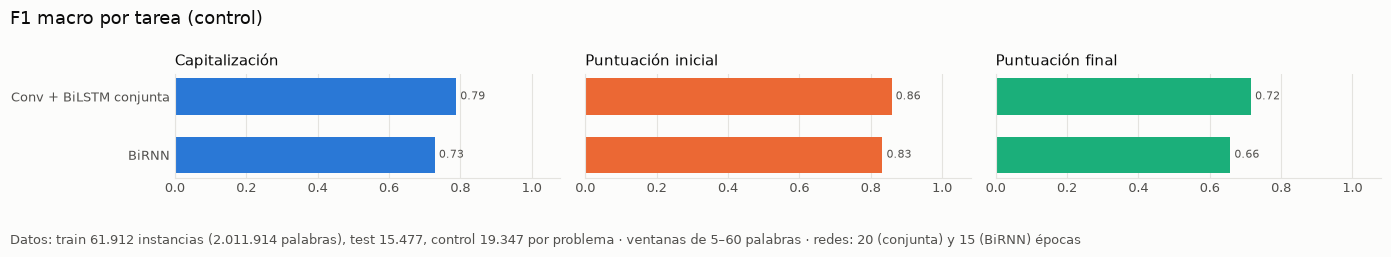

In [5]:
show_and_save(P.plot_f1_by_task(report, SPLIT), "2_f1_por_tarea")

## 3. Curvas de aprendizaje: ¿subajusta o sobreajusta?

F1 macro de cada tarea por época, en train (punteado) y test (lleno). Si las dos curvas suben juntas, el modelo
todavía puede aprender más; si train sigue subiendo y test se estanca o baja, empieza a sobreajustar. El punto
grande es la época con la que se quedó cada red (en la conjunta, elegida con el promedio de las 3 tareas).

**Ojo al comparar train con test**: el F1 de train se calcula durante el entrenamiento, con dropout activo, y el de
test sin dropout. Ahora las dos redes tienen dropout 0.3, así que en las dos la brecha entre train y test subestima
el sobreajuste (test puede quedar por encima de train).

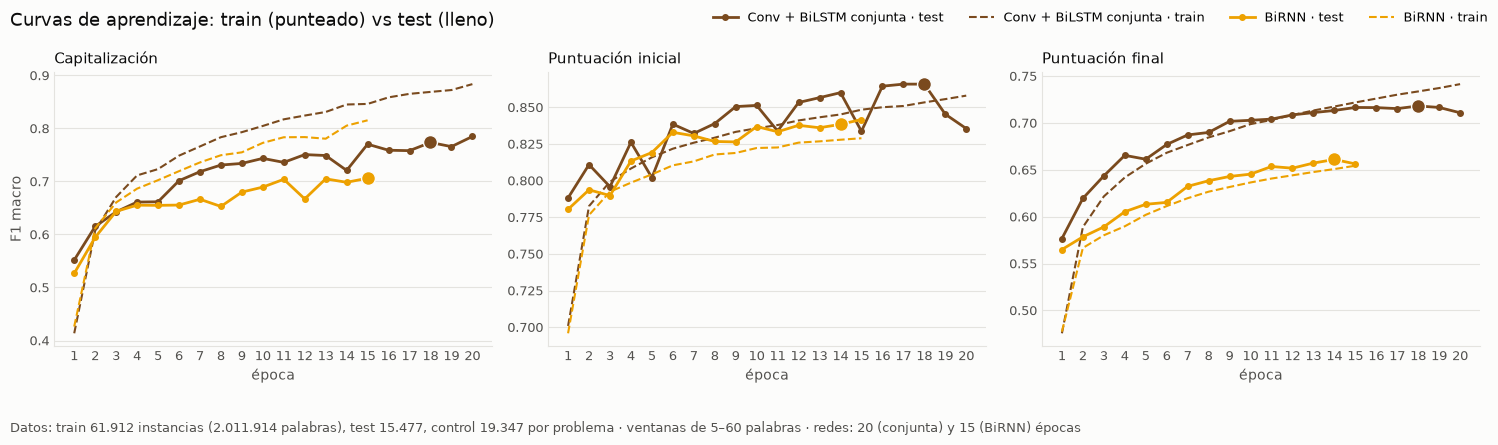

In [6]:
show_and_save(C.plot_train_test_curves(report), "3_curvas_f1_train_test")

## 4. Loss por época

Una curva por red entrenada (la conjunta se entrenó una sola vez para los dos problemas). No comparar escalas entre
paneles: la loss de la conjunta suma las 3 tareas.

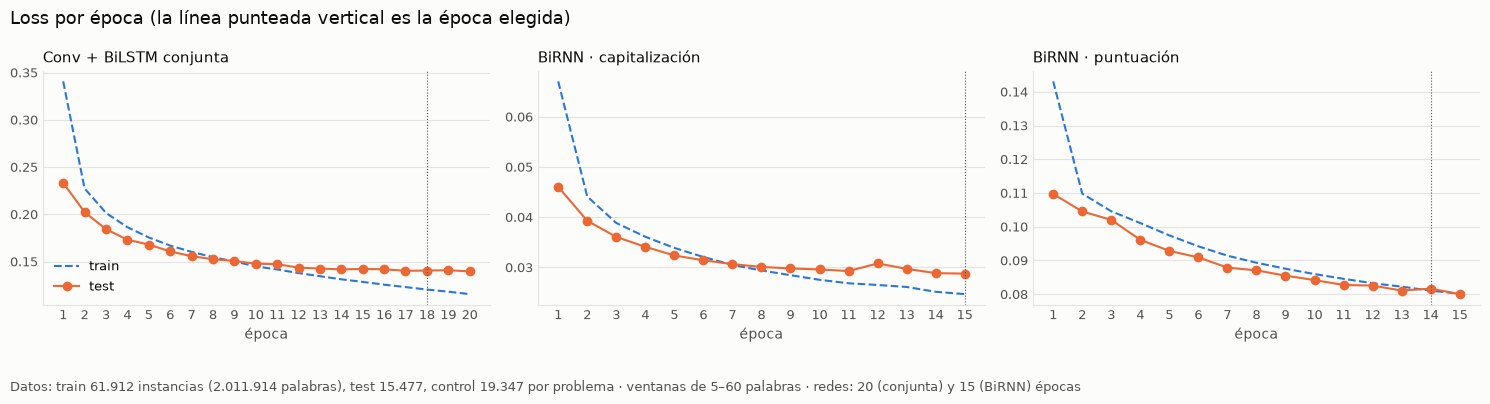

In [7]:
show_and_save(C.plot_loss_curves(report), "4_loss")

## 5. F1 por clase

Las clases raras (`¿`, `?`, `,`, MiXta, MAYÚS) son las que bajan el F1 macro.

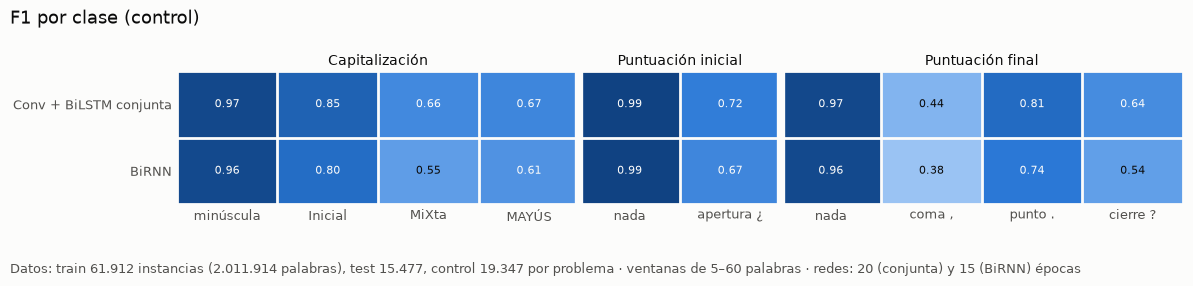

In [8]:
show_and_save(P.plot_class_f1(report, SPLIT), "5_f1_por_clase")

## 6. Precisión vs recall por clase

Con `class_weight_power = 0.25` (igual que el candidato final) precisión y recall de las clases raras deberían
quedar parejos; si recall supera mucho a precisión, la clase se predice de más.

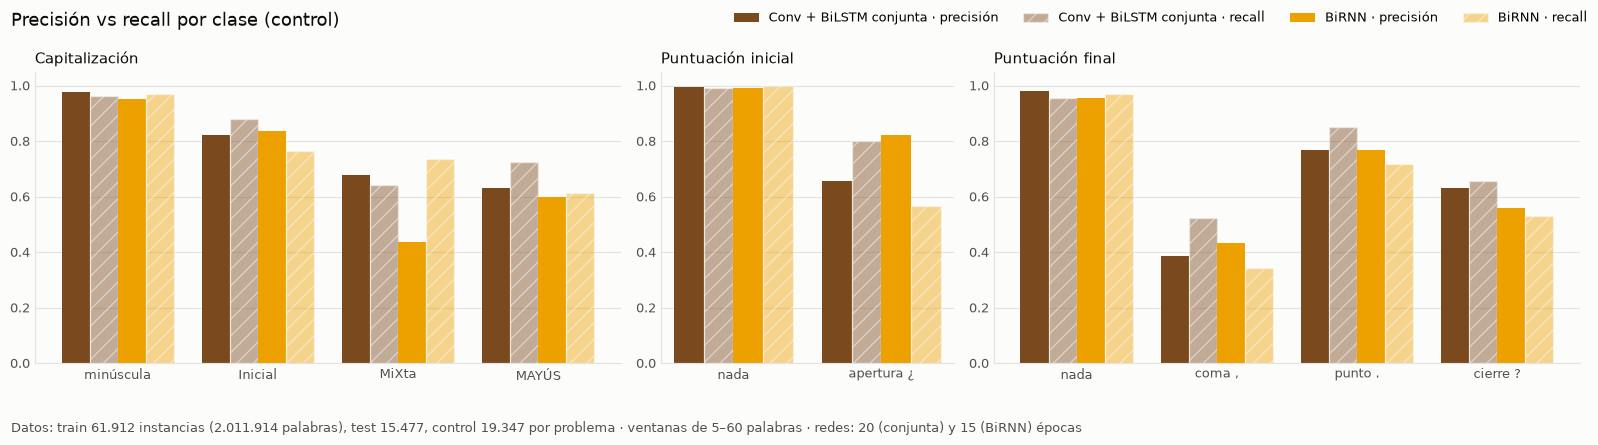

In [9]:
show_and_save(C.plot_precision_recall(report, SPLIT), "6_precision_recall")

## 7. Matrices de confusión

Normalizadas por fila: cada fila muestra a dónde fueron las palabras de esa clase real (la diagonal es el recall).

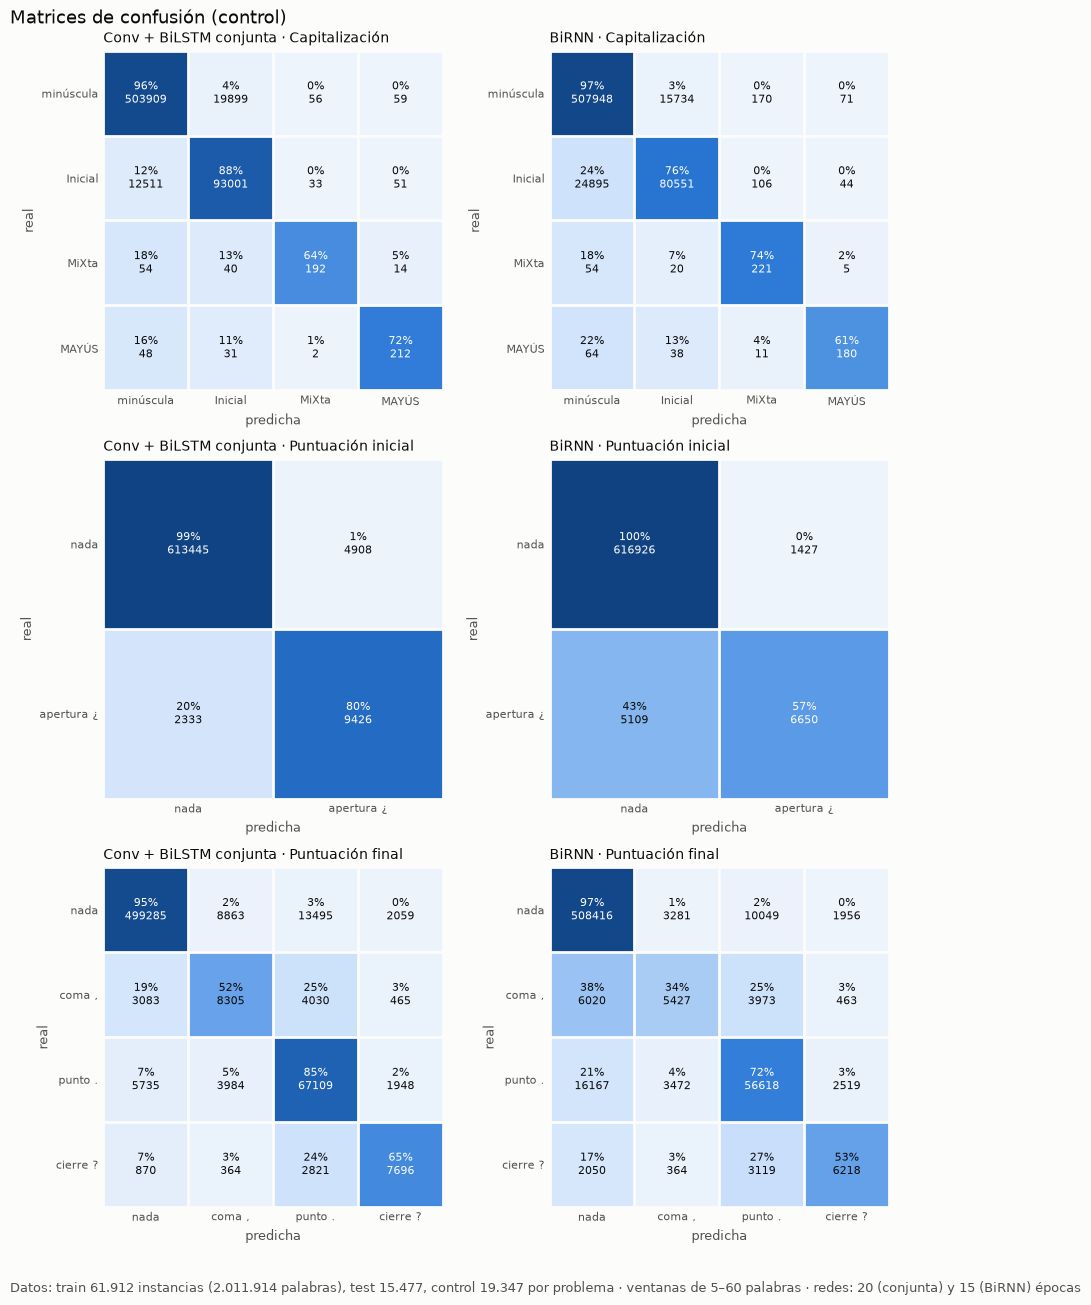

In [10]:
show_and_save(C.plot_confusions_side_by_side(report, SPLIT), "7_confusion")

## 8. Conclusiones

F1 macro en control (entre paréntesis, la diferencia con el candidato final del mismo modelo):

| Modelo | Capitalización | Punt. inicial | Punt. final | Promedio |
|---|---|---|---|---|
| **Conv + BiLSTM conjunta** (20 épocas) | **0.788** (+0.030) | **0.858** (+0.015) | **0.716** (+0.015) | **0.787** (+0.020) |
| BiRNN (dropout + cabeza no lineal, 15 épocas) | 0.728 (+0.030) | 0.833 (+0.019) | 0.657 (+0.025) | 0.739 (+0.024) |

1. **Los dos modelos mejoran en todas las tareas, y la Conv + BiLSTM conjunta sigue siendo el mejor para los dos
   problemas.** Es el modelo a entregar: `models/corridas/2026-11-18__04-38-20/`. En test da 0.786 de promedio, casi igual que en
   control (0.787), así que elegir la época con test no infló el resultado.
2. **La conjunta llegó a su techo cerca de la época 18.** La loss de test casi no baja desde la época 14 (0.142 → 0.140),
   puntuación inicial cae en las épocas 19 y 20 (0.866 → 0.836) y la brecha de capitalización crece (train 0.884 vs test
   0.785 en la época 20, con dropout activo en train, así que la brecha real es mayor). Entrenarla más no ayudaría.
   La extrapolación previa (~0.81 en test con 20 épocas) fue optimista: quedó en 0.786.
3. **En la BiRNN, dropout y cabeza no lineal sumaron +0.024 de promedio**, pero el experimento cambió tres cosas a la
   vez (dropout, cabeza y épocas), así que no se puede atribuir la mejora a cada una. La de capitalización todavía separa
   train de test (0.815 vs 0.706), aunque menos que antes en proporción; la de puntuación tiene test por encima de train y
   sigue subiendo despacio: está limitada por capacidad, no por sobreajuste.
4. **Las clases raras quedaron más equilibradas en la conjunta**: MiXta pasó de precisión 0.53 / recall 0.73 a
   0.68 / 0.64 (F1 0.62 → 0.66), MAYÚS de 0.62 a 0.67 de F1 y `¿` de 0.69 a 0.72. La BiRNN todavía predice MiXta de más
   (precisión 0.44, recall 0.74).
5. **La coma sigue siendo la clase más difícil** (F1 0.44 en la conjunta, 0.38 en la BiRNN) y casi no se movió.
6. **Limitación**: cada configuración se entrenó una sola vez (semilla 12). Las mejoras de ~0.015 pueden estar cerca de
   la variación entre semillas, que no medimos; la de capitalización (+0.030 en los dos modelos) es más robusta.